Part 2 - RNN-Based Temperature Forecasting  
In this part, you will select one of the pre-processed datasets, representing a weather 
station in the Canterbury region, and use it to train an RNN-based model to forecast the 
mean temperature for the following seven days at the selected station. You will then use 
the same trained model, without retraining, to forecast the following seven-day mean 
temperature at the remaining four weather stations.

2.1 Individual RNN Model 
Select one of the five weather stations as the source station and develop an RNN-based 
forecasting model using data from that station for model training and validation. The 
model must use the eight input features at each time step and generate a 7-day multi
step forecast of mean temperature. Model and hyperparameter selection must be 
based on the training and validation data only.

First I import some required libraries to run this model

In [22]:
# Required libraries
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, Dense, Input

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

First I read the whole dataset 

In [23]:
# Read the dataset
df_all = pd.read_csv('../data/clean/Pre-processed Data.csv')

Now I choose the data from only one station 

In [24]:

df = df_all[df_all["Station"] == "CA"]

I have an overview of the dataset to be familiar with it 

In [25]:
print(df.head())
print(df.shape)
df.describe()

         Observation time UTC_x  evap_penman_open  evap_penman_pet  \
6850  2006-02-11 20:00:00+00:00               5.8              5.0   
6851  2006-02-12 20:00:00+00:00              10.6              7.7   
6852  2006-02-13 20:00:00+00:00               3.3              4.2   
6853  2006-02-14 20:00:00+00:00               2.5              2.1   
6854  2006-02-15 20:00:00+00:00               2.6              3.3   

      evap_priestley_taylor  Rainfall [mm]  Speed [m/s]  \
6850                    3.8            0.0         4.90   
6851                    4.7            0.0         5.16   
6852                    4.1            0.0         6.25   
6853                    1.6            0.0         3.34   
6854                    3.1            0.0         4.78   

      Maximum Temperature [Deg C]  Minimum Temperature [Deg C]  \
6850                         25.5                         16.2   
6851                         28.9                         10.8   
6852                      

,evap_penman_open,evap_penman_pet,evap_priestley_taylor,Rainfall [mm],Speed [m/s],Maximum Temperature [Deg C],Minimum Temperature [Deg C],Mean Temperature [Deg C]_x
count,7166.000000,7166.000000,7166.000000,7166.000000,7166.000000,7166.000000,7166.000000,7166.000000
mean,2.912629,2.595507,1.885654,1.835375,3.936895,17.207466,6.377421,11.816822
std,2.223879,1.990411,1.796201,5.488253,1.584089,5.539913,5.227378,4.934037
min,0.000000,0.000000,0.000000,0.000000,0.040000,0.400000,-6.400000,-2.700000
25%,1.400000,0.900000,0.200000,0.000000,2.770000,12.900000,2.300000,7.900000
50%,2.400000,2.100000,1.400000,0.000000,3.810000,16.800000,6.600000,11.600000
75%,4.000000,4.000000,3.200000,0.600000,4.930000,20.800000,10.500000,15.500000
max,15.200000,10.900000,7.500000,85.600000,12.800000,37.100000,22.500000,28.100000


I will check missing value and short date column to be safe 

In [26]:
# Check for missing values
print(df.isnull().sum())

# Convert the data type of the date column in the dataset to Date format
df["Date"] = pd.to_datetime(df["Observation time UTC_x"], format="ISO8601",
    utc=True
)

# Sort the dataframe according to the date
df = df.sort_values("Date").reset_index(drop=True) # index is reset and old index is dropped

Observation time UTC_x         0
evap_penman_open               0
evap_penman_pet                0
evap_priestley_taylor          0
Rainfall [mm]                  0
Speed [m/s]                    0
Maximum Temperature [Deg C]    0
Minimum Temperature [Deg C]    0
Mean Temperature [Deg C]_x     0
Station                        0
dtype: int64


So things are all good, no missing values 

Divide the data into train, val and test

In [27]:
X = df[["evap_penman_open", "evap_penman_pet", "evap_priestley_taylor", "Rainfall [mm]", "Speed [m/s]", 
"Maximum Temperature [Deg C]",
"Minimum Temperature [Deg C]" ,  
"Mean Temperature [Deg C]_x"  
]]

# Train, test, validation split
n = len(X)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train = X.iloc[:train_end]
val = X.iloc[train_end:val_end]
test = X.iloc[val_end:]

print("Train:", train.shape)
print("Validation:", val.shape)
print("Test:", test.shape)

Train: (5016, 8)
Validation: (1075, 8)
Test: (1075, 8)


Scale x an y with x is the all 8 attributes and y is the last attribute

In [28]:
# Normalize temperature
# Scale the four input features
X_scaler = StandardScaler()

# Scale the target separately
y_scaler = StandardScaler()

X_train_scaled = X_scaler.fit_transform(train)

X_val_scaled = X_scaler.transform(val)

X_test_scaled = X_scaler.transform(test)

y_train_scaled = y_scaler.fit_transform(
    train.iloc[:, -1].values.reshape(-1, 1)
)

y_val_scaled = y_scaler.transform(
    val.iloc[:, -1].values.reshape(-1, 1)
)

y_test_scaled = y_scaler.transform(
    test.iloc[:, -1].values.reshape(-1, 1)
)

In the next I create the sequence window of 30 days 

In [29]:
import numpy as np

def create_sequences(X, y, sequence_length, forecast_horizon=7):
    X_seq, y_seq = [], []

    for i in range(len(X) - sequence_length - forecast_horizon + 1):
        X_seq.append(X[i:i + sequence_length])

        # Predict the next 7 days
        y_seq.append(
            y[i + sequence_length:
              i + sequence_length + forecast_horizon].reshape(-1)
        )

    return np.array(X_seq), np.array(y_seq)

In [30]:



sequence_length = 30

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length
)


print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (4980, 30, 8)
y_train: (4980, 7)
X_val: (1039, 30, 8)
y_val: (1039, 7)
X_test: (1039, 30, 8)
y_test: (1039, 7)


Then I run the simple model with squence_length of 30, 8 input and forecast for 7 consecutive days 

In [31]:
RNN_model = Sequential([
    SimpleRNN(64, input_shape=(sequence_length, 8)),
    Dense(7)
])

RNN_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

RNN_model.summary()

c:\Users\vla\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_7 (SimpleRNN)        │ (None, 64)             │         4,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,127 (20.03 KB)

 Trainable params: 5,127 (20.03 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
# Train the model
RNN_history = RNN_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32
)

Epoch 1/30


156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.5174 - mae: 0.5670 - val_loss: 0.4451 - val_mae: 0.5350
Epoch 2/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4185 - mae: 0.5157 - val_loss: 0.4302 - val_mae: 0.5262
Epoch 3/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4196 - mae: 0.5168 - val_loss: 0.4307 - val_mae: 0.5264
Epoch 4/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3986 - mae: 0.5049 - val_loss: 0.4198 - val_mae: 0.5203
Epoch 5/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3907 - mae: 0.4998 - val_loss: 0.4171 - val_mae: 0.5181
Epoch 6/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4130 - mae: 0.5128 - val_loss: 0.4337 - val_mae: 0.5268
Epoch 7/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4093 - mae: 0.5103 - val_loss: 0.5722 - val_mae: 0.6057
Epoch 8/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4444 - mae: 0.5334 - val_loss: 0.4479 - val_mae: 0.5369
Epoch 9/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4121 

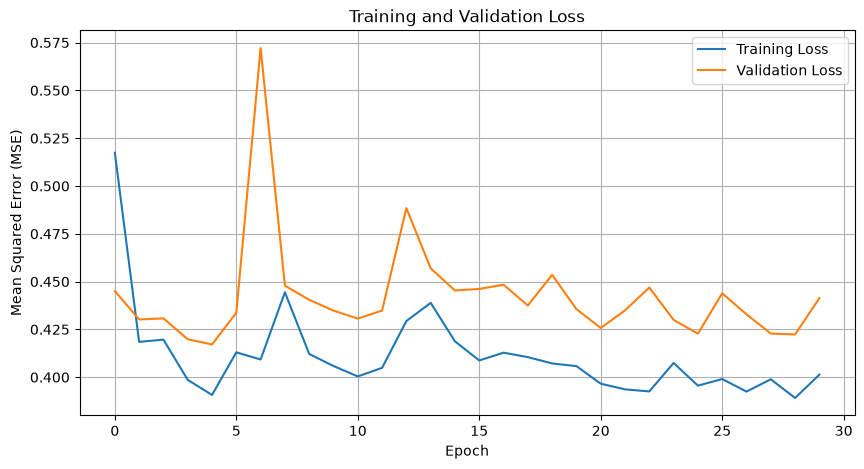

In [33]:
# Training & validation loss
plt.figure(figsize=(10, 5))

plt.plot(
    RNN_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    RNN_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

2.2 Training and Evaluation 
Investigate the effect of different input-window lengths of 7, 14, 30, and 60 days. To 
identify a suitable model architecture, experiment with a simple RNN, LSTM, and GRU. 
Report and analyse the results of the experiments. Once the final model has been 
selected, apply the same trained model to the test datasets from all five weather 
stations without retraining or fine-tuning.  
Report the final model's performance using appropriate evaluation metrics and 
visualisations. Test-set performance must be reported separately for each of the five 
weather stations using the same evaluation procedure. 
Provide a comparison table containing one row for each weather station. The table 
should include the weather station ID, station name, and appropriate evaluation 
metrics for the final model. Clearly distinguish the source station, which was used for 
4 
model training and validation, from the four other stations, which were used only for 
testing.

First with the simple RNN model I will try different input-window lentgs of 7, 14, 30 and 60 days. First I try with sequence length of 7 

In [34]:
sequence_length_1 = 7

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length_1
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length_1
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length_1
)


print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (5003, 7, 8)
y_train: (5003, 7)
X_val: (1062, 7, 8)
y_val: (1062, 7)
X_test: (1062, 7, 8)
y_test: (1062, 7)


In [35]:
RNN_model_1 = Sequential([
    SimpleRNN(64, input_shape=(sequence_length_1, 8)),
    Dense(7)
])

RNN_model_1.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

RNN_model_1.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_8 (SimpleRNN)        │ (None, 64)             │         4,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,127 (20.03 KB)

 Trainable params: 5,127 (20.03 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
# Train the model
RNN_history_1 = RNN_model_1.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32
)

Epoch 1/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.5305 - mae: 0.5756 - val_loss: 0.4576 - val_mae: 0.5424
Epoch 2/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4225 - mae: 0.5189 - val_loss: 0.4439 - val_mae: 0.5335
Epoch 3/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4078 - mae: 0.5103 - val_loss: 0.4452 - val_mae: 0.5335
Epoch 4/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4009 - mae: 0.5056 - val_loss: 0.4378 - val_mae: 0.5298
Epoch 5/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3959 - mae: 0.5032 - val_loss: 0.4404 - val_mae: 0.5328
Epoch 6/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3921 - mae: 0.5003 - val_loss: 0.4399 - val_mae: 0.5312
Epoch 7/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3878 - mae: 0.4978 - val_loss: 0.4398 - val_mae: 0.5300
Epoch 8/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3866 - mae: 0.4968 - val_loss: 0.4401 - val_mae: 0.5274
Epoch 9/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - lo

With sequence length of 7 we have val_loss higher than the ones of the sequence length of 30, for the next step I try the sequence length of 14 

In [37]:
sequence_length_2 = 14

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length_2
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length_2
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length_2
)


RNN_model_2 = Sequential([
    SimpleRNN(64, input_shape=(sequence_length_2, 8)),
    Dense(7)
])

RNN_model_2.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

RNN_model_2.summary()

# Train the model
RNN_history_2 = RNN_model_2.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32
)

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_9 (SimpleRNN)        │ (None, 64)             │         4,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,127 (20.03 KB)

 Trainable params: 5,127 (20.03 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.5162 - mae: 0.5678 - val_loss: 0.4405 - val_mae: 0.5342
Epoch 2/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4062 - mae: 0.5093 - val_loss: 0.4244 - val_mae: 0.5251
Epoch 3/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3966 - mae: 0.5033 - val_loss: 0.4171 - val_mae: 0.5180
Epoch 4/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3884 - mae: 0.4983 - val_loss: 0.4197 - val_mae: 0.5182
Epoch 5/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3872 - mae: 0.4971 - val_loss: 0.4253 - val_mae: 0.5229
Epoch 6/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3808 - mae: 0.4936 - val_loss: 0.4180 - val_mae: 0.5168
Epoch 7/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3764 - mae: 0.4906 - val_loss: 0.4197 - val_mae: 0.5179
Epoch 8/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3774 - mae: 0.4909 - val_loss: 0.4192 - val_mae: 0.5178
Epoch 9/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - lo

val_loss and val_mae are higher than the onew of 30 so I can choose the 30 for now, the next I will try 60

In [38]:
sequence_length_3 = 60

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length_3
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length_3
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length_3
)


RNN_model_3 = Sequential([
    SimpleRNN(64, input_shape=(sequence_length_3, 8)),
    Dense(7)
])

RNN_model_3.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

RNN_model_3.summary()

# Train the model
RNN_history_3 = RNN_model_3.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32
)

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_10 (SimpleRNN)       │ (None, 64)             │         4,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,127 (20.03 KB)

 Trainable params: 5,127 (20.03 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 0.5137 - mae: 0.5674 - val_loss: 0.4443 - val_mae: 0.5371
Epoch 2/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.4038 - mae: 0.5081 - val_loss: 0.4279 - val_mae: 0.5259
Epoch 3/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.3927 - mae: 0.5009 - val_loss: 0.4218 - val_mae: 0.5228
Epoch 4/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.3926 - mae: 0.5012 - val_loss: 0.4281 - val_mae: 0.5239
Epoch 5/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.3876 - mae: 0.4980 - val_loss: 0.4253 - val_mae: 0.5217
Epoch 6/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - loss: 0.3823 - mae: 0.4943 - val_loss: 0.4166 - val_mae: 0.5183
Epoch 7/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 0.3828 - mae: 0.4944 - val_loss: 0.4201 - val_mae: 0.5200
Epoch 8/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.3821 - mae: 0.4945 - val_loss: 0.4208 - val_mae: 0.5216
Epoch 9/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/s

 val_loss and val_mae are higher then the sequence length of 30 so I will stay with the length of 30. AS the data is weather data, the no much impact of the changes in the sequence length on the accuracy of the forecast model is reasonable. In another aspect the simple RNN model might not capture all the complexity of longer sequence length on the forecast. So I will stay with the length of 30. In the next step will fine tunning other parameter of the model. 

First I try to change the number of recurrent layers to 2

In [39]:
sequence_length = 30

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length
)


RNN_model_4 = Sequential([
    SimpleRNN(
        64,
        return_sequences=True,
        input_shape=(sequence_length, 8)
    ),
    SimpleRNN(64),
    Dense(7)
])

RNN_model_4.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

RNN_model_4.summary()

# Train the model
RNN_history_4 = RNN_model_4.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32
)

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_11 (SimpleRNN)       │ (None, 30, 64)         │         4,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_12 (SimpleRNN)       │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,383 (52.28 KB)

 Trainable params: 13,383 (52.28 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - loss: 0.4786 - mae: 0.5507 - val_loss: 0.4360 - val_mae: 0.5295
Epoch 2/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.4016 - mae: 0.5065 - val_loss: 0.4184 - val_mae: 0.5205
Epoch 3/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.3886 - mae: 0.4990 - val_loss: 0.4211 - val_mae: 0.5235
Epoch 4/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.3784 - mae: 0.4915 - val_loss: 0.4212 - val_mae: 0.5216
Epoch 5/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.3738 - mae: 0.4880 - val_loss: 0.4216 - val_mae: 0.5223
Epoch 6/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.3695 - mae: 0.4856 - val_loss: 0.4248 - val_mae: 0.5215
Epoch 7/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.3641 - mae: 0.4816 - val_loss: 0.4138 - val_mae: 0.5165
Epoch 8/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.3551 - mae: 0.4755 - val_loss: 0.4217 - val_mae: 0.5198
Epoch 9/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/

we can see the val loss and val mae are little higher than the one layer so I will stay with the one layer. In the next step I will try different hidden unit first I try with 128 

In [40]:
sequence_length = 30

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length
)


RNN_model_5 = Sequential([
    SimpleRNN(128, input_shape=(sequence_length, 8)),
        Dense(7)
    ])
 

RNN_model_5.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

RNN_model_5.summary()

# Train the model
RNN_history_5 = RNN_model_5.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32
)

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_13 (SimpleRNN)       │ (None, 128)            │        17,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,439 (72.03 KB)

 Trainable params: 18,439 (72.03 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.4571 - mae: 0.5380 - val_loss: 0.4465 - val_mae: 0.5328
Epoch 2/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.4025 - mae: 0.5072 - val_loss: 0.4112 - val_mae: 0.5148
Epoch 3/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3995 - mae: 0.5054 - val_loss: 0.4239 - val_mae: 0.5217
Epoch 4/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.4131 - mae: 0.5134 - val_loss: 0.4285 - val_mae: 0.5250
Epoch 5/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3988 - mae: 0.5049 - val_loss: 0.4216 - val_mae: 0.5199
Epoch 6/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3972 - mae: 0.5032 - val_loss: 0.4168 - val_mae: 0.5180
Epoch 7/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3901 - mae: 0.5003 - val_loss: 0.4515 - val_mae: 0.5399
Epoch 8/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3905 - mae: 0.4998 - val_loss: 0.4325 - val_mae: 0.5263
Epoch 9/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - lo

So I see lat val_loss and val_mae are higher than the number of unit 64 so I will stay with 64. In the next step, I will try the drop_out rate of 0.2

In [41]:
from tensorflow.keras.layers import SimpleRNN, Dense, Dropout
sequence_length = 30

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length
)


RNN_model_6 = Sequential([
    SimpleRNN(64, input_shape=(sequence_length, 8)),
    Dropout(0.2),
    Dense(7)
    ])
 

RNN_model_6.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

RNN_model_6.summary()

# Train the model
RNN_history_6 = RNN_model_6.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32
)

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_14 (SimpleRNN)       │ (None, 64)             │         4,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,127 (20.03 KB)

 Trainable params: 5,127 (20.03 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 0.6005 - mae: 0.6163 - val_loss: 0.4564 - val_mae: 0.5438
Epoch 2/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4649 - mae: 0.5429 - val_loss: 0.4332 - val_mae: 0.5317
Epoch 3/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4312 - mae: 0.5249 - val_loss: 0.4167 - val_mae: 0.5202
Epoch 4/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4156 - mae: 0.5153 - val_loss: 0.4149 - val_mae: 0.5200
Epoch 5/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4030 - mae: 0.5078 - val_loss: 0.4164 - val_mae: 0.5179
Epoch 6/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3992 - mae: 0.5042 - val_loss: 0.4093 - val_mae: 0.5168
Epoch 7/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3917 - mae: 0.5007 - val_loss: 0.4091 - val_mae: 0.5145
Epoch 8/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3868 - mae: 0.4967 - val_loss: 0.4174 - val_mae: 0.5196
Epoch 9/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - lo

So we can see that the val_loss and val_mae are lower than without dropout rate so I will not use this dropout rate. In the next step, I will try another learning rate. Because the learning rate of adam default is 0.001 I will try the learning rate of 0.0001 optimizer=Adam(learning_rate=0.0001) rate,

In [42]:
from tensorflow.keras.optimizers import Adam
sequence_length = 30

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length
)


RNN_model_7 = Sequential([
    SimpleRNN(64, input_shape=(sequence_length, 8)),
    
    Dense(7)
    ])
 

RNN_model_7.compile(
    optimizer= Adam(learning_rate=0.0001),
    loss="mse",
    metrics=["mae"]
)

RNN_model_7.summary()

# Train the model
RNN_history_7 = RNN_model_7.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32
)

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_15 (SimpleRNN)       │ (None, 64)             │         4,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,127 (20.03 KB)

 Trainable params: 5,127 (20.03 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.9890 - mae: 0.7855 - val_loss: 0.6955 - val_mae: 0.6611
Epoch 2/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.5952 - mae: 0.6127 - val_loss: 0.5926 - val_mae: 0.6125
Epoch 3/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.5279 - mae: 0.5788 - val_loss: 0.5436 - val_mae: 0.5889
Epoch 4/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4889 - mae: 0.5576 - val_loss: 0.5102 - val_mae: 0.5723
Epoch 5/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4628 - mae: 0.5429 - val_loss: 0.4865 - val_mae: 0.5600
Epoch 6/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4431 - mae: 0.5318 - val_loss: 0.4681 - val_mae: 0.5499
Epoch 7/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4278 - mae: 0.5226 - val_loss: 0.4549 - val_mae: 0.5429
Epoch 8/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4163 - mae: 0.5159 - val_loss: 0.4450 - val_mae: 0.5372
Epoch 9/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - lo

 we can see that the val_loss and val_mae are little higher so I will stay with learning rate of 0.0001. In the next step I will change the batch size to 16

In [43]:
from tensorflow.keras.optimizers import Adam
sequence_length = 30

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length
)


RNN_model_8 = Sequential([
    SimpleRNN(64, input_shape=(sequence_length, 8)),
    Dropout(0.2),
    Dense(7)
    ])
 

RNN_model_8.compile(
    optimizer= Adam(learning_rate=0.0001),
    loss="mse",
    metrics=["mae"]
)

RNN_model_8.summary()

# Train the model
RNN_history_8 = RNN_model_8.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=16
)

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_16 (SimpleRNN)       │ (None, 64)             │         4,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,127 (20.03 KB)

 Trainable params: 5,127 (20.03 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
312/312 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.8755 - mae: 0.7407 - val_loss: 0.5939 - val_mae: 0.6146
Epoch 2/30
312/312 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.6536 - mae: 0.6455 - val_loss: 0.5150 - val_mae: 0.5751
Epoch 3/30
312/312 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.5827 - mae: 0.6090 - val_loss: 0.4756 - val_mae: 0.5550
Epoch 4/30
312/312 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.5433 - mae: 0.5881 - val_loss: 0.4544 - val_mae: 0.5430
Epoch 5/30
312/312 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.5174 - mae: 0.5742 - val_loss: 0.4436 - val_mae: 0.5358
Epoch 6/30
312/312 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.4979 - mae: 0.5639 - val_loss: 0.4379 - val_mae: 0.5321
Epoch 7/30
312/312 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.4849 - mae: 0.5572 - val_loss: 0.4308 - val_mae: 0.5282
Epoch 8/30
312/312 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4738 - mae: 0.5490 - val_loss: 0.4258 - val_mae: 0.5249
Epoch 9/30
312/312 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - lo

So the val_loss and val_mae are higher so I will stay with the batch size of 32. In the next step I wil try number of training epochs, we will try the number of training epochss of 100 with the addition of early stopping 

In [44]:
from tensorflow import keras
from tensorflow.keras.callbacks import EarlyStopping
sequence_length = 30

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length
)


RNN_model_9 = Sequential([
    SimpleRNN(64, input_shape=(sequence_length, 8)),
    Dropout(0.2),
    Dense(7)
    ])

early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

RNN_model_9.compile(
    optimizer= "adam",
    loss="mse",
    metrics=["mae"]
)

RNN_model_9.summary()

# Train the model
RNN_history_9 = RNN_model_9.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32, 
    callbacks=[early_stop]
)

Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_17 (SimpleRNN)       │ (None, 64)             │         4,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,127 (20.03 KB)

 Trainable params: 5,127 (20.03 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
156/156 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 0.5946 - mae: 0.6108 - val_loss: 0.4442 - val_mae: 0.5343
Epoch 2/100
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4677 - mae: 0.5457 - val_loss: 0.4257 - val_mae: 0.5245
Epoch 3/100
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4335 - mae: 0.5262 - val_loss: 0.4163 - val_mae: 0.5192
Epoch 4/100
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4172 - mae: 0.5162 - val_loss: 0.4119 - val_mae: 0.5166
Epoch 5/100
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4035 - mae: 0.5078 - val_loss: 0.4070 - val_mae: 0.5149
Epoch 6/100
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.3981 - mae: 0.5041 - val_loss: 0.4164 - val_mae: 0.5167
Epoch 7/100
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3912 - mae: 0.5007 - val_loss: 0.4128 - val_mae: 0.5178
Epoch 8/100
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3845 - mae: 0.4967 - val_loss: 0.4215 - val_mae: 0.5220
Epoch 9/100
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/

So we can see that val_loss and val_mea increase so I will stay with the epoches of 30. So the final model for RNN would be the sequence length of 30, 1 dropout, input 64, epoches 30, batch size 32 and Adam learning rate 0.0001 which is the model RNN_model_7 and it produced the loss and mae like this loss:  loss: 0.3696 - mae: 0.4856 - val_loss: 0.4037 - val_mae: 0.5104

In the next step I will try the LSTM

In [45]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import LSTM, Dense


sequence_length_lstm_1 = 30

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length_lstm_1
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length_lstm_1
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length_lstm_1
)




LSTM_model_1 = Sequential([
    LSTM(64, input_shape=(sequence_length_lstm_1, 8)),
    Dense(7)
])

LSTM_model_1.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

LSTM_model_1.summary()



# Train the model
LSTM_history = LSTM_model_1.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32
)

Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        18,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,143 (74.78 KB)

 Trainable params: 19,143 (74.78 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - loss: 0.4506 - mae: 0.5358 - val_loss: 0.4211 - val_mae: 0.5222
Epoch 2/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.3800 - mae: 0.4939 - val_loss: 0.4096 - val_mae: 0.5151
Epoch 3/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.3727 - mae: 0.4886 - val_loss: 0.4060 - val_mae: 0.5118
Epoch 4/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.3672 - mae: 0.4845 - val_loss: 0.3967 - val_mae: 0.5071
Epoch 5/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.3613 - mae: 0.4796 - val_loss: 0.3945 - val_mae: 0.5031
Epoch 6/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.3585 - mae: 0.4774 - val_loss: 0.3991 - val_mae: 0.5064
Epoch 7/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.3543 - mae: 0.4748 - val_loss: 0.4024 - val_mae: 0.5085
Epoch 8/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.3508 - mae: 0.4721 - val_loss: 0.4007 - val_mae: 0.5068
Epoch 9/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/

In the next step I will try with the sequence length of 7

In [46]:



sequence_length_lstm_2 = 7

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length_lstm_2
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length_lstm_2
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length_lstm_2
)




LSTM_model_2 = Sequential([
    LSTM(64, input_shape=(sequence_length_lstm_2, 8)),
    Dense(7)
])

LSTM_model_2.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

LSTM_model_2.summary()



# Train the model
LSTM_history_2 = LSTM_model_2.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32
)

Model: "sequential_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 64)             │        18,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,143 (74.78 KB)

 Trainable params: 19,143 (74.78 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.4531 - mae: 0.5392 - val_loss: 0.4358 - val_mae: 0.5300
Epoch 2/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3973 - mae: 0.5043 - val_loss: 0.4402 - val_mae: 0.5300
Epoch 3/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3883 - mae: 0.4983 - val_loss: 0.4260 - val_mae: 0.5229
Epoch 4/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3831 - mae: 0.4945 - val_loss: 0.4274 - val_mae: 0.5235
Epoch 5/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3807 - mae: 0.4932 - val_loss: 0.4300 - val_mae: 0.5237
Epoch 6/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3769 - mae: 0.4902 - val_loss: 0.4335 - val_mae: 0.5256
Epoch 7/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3755 - mae: 0.4889 - val_loss: 0.4349 - val_mae: 0.5279
Epoch 8/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3726 - mae: 0.4871 - val_loss: 0.4387 - val_mae: 0.5291
Epoch 9/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - lo

So I see that val_loss and val_mae are smaller so I will use sequence length of 7 for now, next I will try another sequence of 14

In [47]:



sequence_length_lstm_3 = 14

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length_lstm_3
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length_lstm_3
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length_lstm_3
)




LSTM_model_3 = Sequential([
    LSTM(64, input_shape=(sequence_length_lstm_3, 8)),
    Dense(7)
])

LSTM_model_3.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

LSTM_model_3.summary()



# Train the model
LSTM_history_3 = LSTM_model_3.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32
)

Model: "sequential_18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 64)             │        18,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,143 (74.78 KB)

 Trainable params: 19,143 (74.78 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 0.4415 - mae: 0.5310 - val_loss: 0.4198 - val_mae: 0.5202
Epoch 2/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.3836 - mae: 0.4961 - val_loss: 0.4162 - val_mae: 0.5178
Epoch 3/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.3750 - mae: 0.4902 - val_loss: 0.4122 - val_mae: 0.5146
Epoch 4/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.3702 - mae: 0.4861 - val_loss: 0.4100 - val_mae: 0.5141
Epoch 5/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.3675 - mae: 0.4844 - val_loss: 0.4149 - val_mae: 0.5165
Epoch 6/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.3629 - mae: 0.4811 - val_loss: 0.4193 - val_mae: 0.5181
Epoch 7/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.3611 - mae: 0.4797 - val_loss: 0.4107 - val_mae: 0.5147
Epoch 8/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.3579 - mae: 0.4775 - val_loss: 0.4060 - val_mae: 0.5120
Epoch 9/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - l

val_loss and val_mae for this sequence is higher than those of 7, so I will stay with 7 for now and I will try 60 next

In [48]:



sequence_length_lstm_4 = 60

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length_lstm_4
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length_lstm_4
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length_lstm_4
)




LSTM_model_4 = Sequential([
    LSTM(64, input_shape=(sequence_length_lstm_4, 8)),
    Dense(7)
])

LSTM_model_4.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

LSTM_model_4.summary()



# Train the model
LSTM_history_4 = LSTM_model_4.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32
)

Model: "sequential_19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_3 (LSTM)                   │ (None, 64)             │        18,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,143 (74.78 KB)

 Trainable params: 19,143 (74.78 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 8s 25ms/step - loss: 0.4414 - mae: 0.5314 - val_loss: 0.4244 - val_mae: 0.5230
Epoch 2/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.3805 - mae: 0.4941 - val_loss: 0.4109 - val_mae: 0.5179
Epoch 3/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - loss: 0.3726 - mae: 0.4891 - val_loss: 0.4021 - val_mae: 0.5102
Epoch 4/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.3673 - mae: 0.4853 - val_loss: 0.4001 - val_mae: 0.5092
Epoch 5/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.3625 - mae: 0.4819 - val_loss: 0.4002 - val_mae: 0.5090
Epoch 6/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.3576 - mae: 0.4783 - val_loss: 0.4123 - val_mae: 0.5156
Epoch 7/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - loss: 0.3536 - mae: 0.4742 - val_loss: 0.4001 - val_mae: 0.5096
Epoch 8/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - loss: 0.3511 - mae: 0.4724 - val_loss: 0.3964 - val_mae: 0.5078
Epoch 9/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/

The val_loss and val_mae here are still higher than the ones of 7 so I will keep the input-window length of 7. In the next step, I will try other parameter. The first one is the layer, I will add another layer

In [49]:



sequence_length_lstm_2 = 7

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length_lstm_2
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length_lstm_2
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length_lstm_2
)




LSTM_model_2 = Sequential([
    LSTM(64, input_shape=(sequence_length_lstm_2 , 8), return_sequences=True),

    LSTM(64),
    Dense(7)
])

LSTM_model_2.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

LSTM_model_2.summary()



# Train the model
LSTM_history_2 = LSTM_model_2.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32
)

Model: "sequential_20"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 7, 64)          │        18,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 52,167 (203.78 KB)

 Trainable params: 52,167 (203.78 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - loss: 0.4549 - mae: 0.5399 - val_loss: 0.4457 - val_mae: 0.5343
Epoch 2/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.4036 - mae: 0.5092 - val_loss: 0.4398 - val_mae: 0.5336
Epoch 3/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.3933 - mae: 0.5025 - val_loss: 0.4374 - val_mae: 0.5293
Epoch 4/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.3886 - mae: 0.4987 - val_loss: 0.4301 - val_mae: 0.5274
Epoch 5/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.3823 - mae: 0.4936 - val_loss: 0.4352 - val_mae: 0.5297
Epoch 6/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.3781 - mae: 0.4909 - val_loss: 0.4325 - val_mae: 0.5266
Epoch 7/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.3736 - mae: 0.4875 - val_loss: 0.4388 - val_mae: 0.5301
Epoch 8/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.3713 - mae: 0.4858 - val_loss: 0.4325 - val_mae: 0.5272
Epoch 9/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - 

The val_mae and val_loss still higher than the ones of 1 layer, so I will stay with one layer, in the next I will try the number of hidden units of 128

In [50]:



sequence_length_lstm_2 = 7

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length_lstm_2
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length_lstm_2
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length_lstm_2
)




LSTM_model_3 = Sequential([
    LSTM(128, input_shape=(sequence_length_lstm_2 , 8)),

    
    Dense(7)
])

LSTM_model_3.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

LSTM_model_3.summary()


# Train the model
LSTM_history_3 = LSTM_model_3.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32
)

Model: "sequential_21"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_6 (LSTM)                   │ (None, 128)            │        70,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71,047 (277.53 KB)

 Trainable params: 71,047 (277.53 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 0.4383 - mae: 0.5307 - val_loss: 0.4323 - val_mae: 0.5261
Epoch 2/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.3950 - mae: 0.5026 - val_loss: 0.4303 - val_mae: 0.5260
Epoch 3/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.3870 - mae: 0.4973 - val_loss: 0.4290 - val_mae: 0.5241
Epoch 4/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.3831 - mae: 0.4944 - val_loss: 0.4286 - val_mae: 0.5249
Epoch 5/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.3786 - mae: 0.4909 - val_loss: 0.4289 - val_mae: 0.5227
Epoch 6/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.3760 - mae: 0.4896 - val_loss: 0.4315 - val_mae: 0.5245
Epoch 7/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.3746 - mae: 0.4884 - val_loss: 0.4311 - val_mae: 0.5268
Epoch 8/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.3706 - mae: 0.4857 - val_loss: 0.4320 - val_mae: 0.5256
Epoch 9/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - 

val_loss and val_mae here are higher so I will stay with number of unit 64 In the next I will change to the learning rate of 0.0001

In [51]:



sequence_length_lstm_2 = 7

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length_lstm_2
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length_lstm_2
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length_lstm_2
)




LSTM_model_4 = Sequential([
    LSTM(64, input_shape=(sequence_length_lstm_2 , 8)),

    
    Dense(7)
])

LSTM_model_4.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="mse",
    metrics=["mae"]
)

LSTM_model_4.summary()



# Train the model
LSTM_history_4 = LSTM_model_4.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32
)

Model: "sequential_22"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_7 (LSTM)                   │ (None, 64)             │        18,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,143 (74.78 KB)

 Trainable params: 19,143 (74.78 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 0.7335 - mae: 0.6994 - val_loss: 0.5630 - val_mae: 0.6043
Epoch 2/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4766 - mae: 0.5588 - val_loss: 0.4688 - val_mae: 0.5498
Epoch 3/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4369 - mae: 0.5322 - val_loss: 0.4569 - val_mae: 0.5425
Epoch 4/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4260 - mae: 0.5248 - val_loss: 0.4497 - val_mae: 0.5381
Epoch 5/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4184 - mae: 0.5196 - val_loss: 0.4440 - val_mae: 0.5348
Epoch 6/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4127 - mae: 0.5157 - val_loss: 0.4411 - val_mae: 0.5327
Epoch 7/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4081 - mae: 0.5124 - val_loss: 0.4383 - val_mae: 0.5309
Epoch 8/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4045 - mae: 0.5097 - val_loss: 0.4347 - val_mae: 0.5291
Epoch 9/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - l

val_loss and val_mea are higher than default adam so I will keep at this learning rate of 0.0001. In the next I will chaneg the batch size to 16  

In [52]:



sequence_length_lstm_2 = 7

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length_lstm_2
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length_lstm_2
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length_lstm_2
)




LSTM_model_5 = Sequential([
    LSTM(64, input_shape=(sequence_length_lstm_2 , 8)),

   
    Dense(7)
])

LSTM_model_5.compile(
    optimizer= Adam(learning_rate=0.0001),
    loss="mse",
    metrics=["mae"]
)

LSTM_model_5.summary()



# Train the model
LSTM_history_5 = LSTM_model_5.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=16
)

Model: "sequential_23"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_8 (LSTM)                   │ (None, 64)             │        18,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,143 (74.78 KB)

 Trainable params: 19,143 (74.78 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - loss: 0.5904 - mae: 0.6225 - val_loss: 0.4719 - val_mae: 0.5498
Epoch 2/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4374 - mae: 0.5318 - val_loss: 0.4539 - val_mae: 0.5402
Epoch 3/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4230 - mae: 0.5221 - val_loss: 0.4446 - val_mae: 0.5347
Epoch 4/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4130 - mae: 0.5154 - val_loss: 0.4369 - val_mae: 0.5307
Epoch 5/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4065 - mae: 0.5108 - val_loss: 0.4338 - val_mae: 0.5282
Epoch 6/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4018 - mae: 0.5076 - val_loss: 0.4316 - val_mae: 0.5273
Epoch 7/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.3983 - mae: 0.5050 - val_loss: 0.4304 - val_mae: 0.5263
Epoch 8/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3958 - mae: 0.5031 - val_loss: 0.4284 - val_mae: 0.5248
Epoch 9/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - lo

val_loss and val_mae are lowee so I will stay with batch size of 16. In the next step I will try drop out of 0.2 

In [53]:



sequence_length_lstm_2 = 7

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length_lstm_2
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length_lstm_2
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length_lstm_2
)




LSTM_model_6 = Sequential([
    LSTM(64, input_shape=(sequence_length_lstm_2 , 8)),
    Dropout(0.2),
    
    Dense(7)
])

LSTM_model_6.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="mse",
    metrics=["mae"]
)

LSTM_model_6.summary()



# Train the model
LSTM_history_6 = LSTM_model_6.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=16
)

Model: "sequential_24"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_9 (LSTM)                   │ (None, 64)             │        18,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,143 (74.78 KB)

 Trainable params: 19,143 (74.78 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.6802 - mae: 0.6672 - val_loss: 0.4798 - val_mae: 0.5572
Epoch 2/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4595 - mae: 0.5451 - val_loss: 0.4565 - val_mae: 0.5426
Epoch 3/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4397 - mae: 0.5329 - val_loss: 0.4458 - val_mae: 0.5365
Epoch 4/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4298 - mae: 0.5268 - val_loss: 0.4402 - val_mae: 0.5335
Epoch 5/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4243 - mae: 0.5225 - val_loss: 0.4356 - val_mae: 0.5304
Epoch 6/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4180 - mae: 0.5186 - val_loss: 0.4328 - val_mae: 0.5284
Epoch 7/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4129 - mae: 0.5150 - val_loss: 0.4309 - val_mae: 0.5275
Epoch 8/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4113 - mae: 0.5147 - val_loss: 0.4307 - val_mae: 0.5264
Epoch 9/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - lo

val_loss and val_mae here are little higher than without the drop out but loss and mae are little higher so I will stay without the dropout. Next will try with the epoches of 100 and early stop

In [54]:



sequence_length_lstm_2 = 7

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length_lstm_2
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length_lstm_2
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length_lstm_2
)




LSTM_model_6 = Sequential([
    LSTM(64, input_shape=(sequence_length_lstm_2 , 8)),
    
    
    Dense(7)
])
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

LSTM_model_6.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="mse",
    metrics=["mae"]
)

LSTM_model_6.summary()



# Train the model
LSTM_history_6 = LSTM_model_6.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=16, 
    callbacks = early_stop
)

Model: "sequential_25"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_10 (LSTM)                  │ (None, 64)             │        18,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,143 (74.78 KB)

 Trainable params: 19,143 (74.78 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.6416 - mae: 0.6481 - val_loss: 0.4773 - val_mae: 0.5544
Epoch 2/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.4392 - mae: 0.5320 - val_loss: 0.4536 - val_mae: 0.5404
Epoch 3/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.4215 - mae: 0.5212 - val_loss: 0.4440 - val_mae: 0.5343
Epoch 4/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.4110 - mae: 0.5140 - val_loss: 0.4361 - val_mae: 0.5308
Epoch 5/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4049 - mae: 0.5098 - val_loss: 0.4336 - val_mae: 0.5293
Epoch 6/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4008 - mae: 0.5070 - val_loss: 0.4329 - val_mae: 0.5280
Epoch 7/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3973 - mae: 0.5045 - val_loss: 0.4311 - val_mae: 0.5266
Epoch 8/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.3947 - mae: 0.5026 - val_loss: 0.4298 - val_mae: 0.5259
Epoch 9/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/

val_loss and val_mae are little lower than without early stop and 30 epoches so this will be the model with parameters that I use for LSTM. 

So for the LSTM model the final model that gave me the lowest val_loss and val_mea are the ones with sequence length of 7, 1 layer, 1 dropout, number of unit 64, batch size 16 and epoches 100 with early stop, learning rate 0.0001 adam and here is the LSTM_model_6 and it gave me these losss and mae loss: loss: 0.3754 - mae: 0.4881 - val_loss: 0.4216 - val_mae: 0.5189, which we can see that higher than the final RNN model that I identified above loss: 0.3696 - mae: 0.4856 - val_loss: 0.4037 - val_mae: 0.5104, so at this statge I will select the RNN_model_7. Next I will try the GRU model 

In [55]:

from tensorflow.keras.layers import GRU, Dense

sequence_length_gru_1 = 30

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length_gru_1
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length_gru_1
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length_gru_1
)




GRU_model_1 = Sequential([
    GRU(64, input_shape=(sequence_length_gru_1, 8)),
    Dense(7)
])

GRU_model_1.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

GRU_model_1.summary()


GRU_history_1 = GRU_model_1.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32
)



Model: "sequential_26"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 64)             │        14,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,663 (57.28 KB)

 Trainable params: 14,663 (57.28 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.4430 - mae: 0.5300 - val_loss: 0.4191 - val_mae: 0.5184
Epoch 2/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.3818 - mae: 0.4937 - val_loss: 0.4055 - val_mae: 0.5108
Epoch 3/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.3752 - mae: 0.4893 - val_loss: 0.4035 - val_mae: 0.5094
Epoch 4/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.3703 - mae: 0.4859 - val_loss: 0.4092 - val_mae: 0.5115
Epoch 5/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.3688 - mae: 0.4845 - val_loss: 0.4039 - val_mae: 0.5085
Epoch 6/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.3651 - mae: 0.4817 - val_loss: 0.4053 - val_mae: 0.5092
Epoch 7/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.3622 - mae: 0.4800 - val_loss: 0.4183 - val_mae: 0.5161
Epoch 8/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.3600 - mae: 0.4782 - val_loss: 0.3967 - val_mae: 0.5055
Epoch 9/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step 

In the next step I will try with input window being 7

In [56]:

from tensorflow.keras.layers import GRU, Dense

sequence_length_gru_2 = 7

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length_gru_2
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length_gru_2
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length_gru_2
)




GRU_model_2 = Sequential([
    GRU(64, input_shape=(sequence_length_gru_2, 8)),
    Dense(7)
])

GRU_model_2.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

GRU_model_2.summary()


GRU_history_2 = GRU_model_2.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32
)



Model: "sequential_27"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_1 (GRU)                     │ (None, 64)             │        14,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,663 (57.28 KB)

 Trainable params: 14,663 (57.28 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.4541 - mae: 0.5394 - val_loss: 0.4306 - val_mae: 0.5256
Epoch 2/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3949 - mae: 0.5013 - val_loss: 0.4242 - val_mae: 0.5201
Epoch 3/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.3891 - mae: 0.4975 - val_loss: 0.4224 - val_mae: 0.5188
Epoch 4/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.3846 - mae: 0.4945 - val_loss: 0.4270 - val_mae: 0.5214
Epoch 5/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3828 - mae: 0.4933 - val_loss: 0.4201 - val_mae: 0.5185
Epoch 6/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3796 - mae: 0.4914 - val_loss: 0.4237 - val_mae: 0.5201
Epoch 7/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3769 - mae: 0.4899 - val_loss: 0.4286 - val_mae: 0.5230
Epoch 8/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3733 - mae: 0.4871 - val_loss: 0.4278 - val_mae: 0.5231
Epoch 9/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - lo

val loss and val mae are lower so I will stay with 7, in the next I will try the sequence length of 14

In [57]:

from tensorflow.keras.layers import GRU, Dense

sequence_length_gru_3 = 14

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length_gru_3
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length_gru_3
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length_gru_3
)




GRU_model_3 = Sequential([
    GRU(64, input_shape=(sequence_length_gru_3, 8)),
    Dense(7)
])

GRU_model_3.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

GRU_model_3.summary()


GRU_history_3 = GRU_model_3.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32
)



Model: "sequential_28"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_2 (GRU)                     │ (None, 64)             │        14,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,663 (57.28 KB)

 Trainable params: 14,663 (57.28 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 0.4547 - mae: 0.5387 - val_loss: 0.4178 - val_mae: 0.5176
Epoch 2/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.3829 - mae: 0.4943 - val_loss: 0.4192 - val_mae: 0.5184
Epoch 3/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.3779 - mae: 0.4911 - val_loss: 0.4101 - val_mae: 0.5132
Epoch 4/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.3746 - mae: 0.4887 - val_loss: 0.4175 - val_mae: 0.5165
Epoch 5/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.3710 - mae: 0.4864 - val_loss: 0.4231 - val_mae: 0.5197
Epoch 6/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.3708 - mae: 0.4857 - val_loss: 0.4150 - val_mae: 0.5155
Epoch 7/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.3672 - mae: 0.4840 - val_loss: 0.4156 - val_mae: 0.5163
Epoch 8/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.3638 - mae: 0.4812 - val_loss: 0.4169 - val_mae: 0.5163
Epoch 9/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - l

val_loss and val_mae are higher so I will stay with 7, next I will try sequence length of 60

In [58]:

from tensorflow.keras.layers import GRU, Dense

sequence_length_gru_4 = 60

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length_gru_4
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length_gru_4
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length_gru_4
)




GRU_model_4 = Sequential([
    GRU(64, input_shape=(sequence_length_gru_4, 8)),
    Dense(7)
])

GRU_model_4.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

GRU_model_4.summary()


GRU_history_4 = GRU_model_4.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32
)



Model: "sequential_29"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_3 (GRU)                     │ (None, 64)             │        14,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,663 (57.28 KB)

 Trainable params: 14,663 (57.28 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 7s 29ms/step - loss: 0.4681 - mae: 0.5435 - val_loss: 0.4261 - val_mae: 0.5233
Epoch 2/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.3833 - mae: 0.4946 - val_loss: 0.4103 - val_mae: 0.5132
Epoch 3/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.3753 - mae: 0.4897 - val_loss: 0.4079 - val_mae: 0.5129
Epoch 4/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - loss: 0.3698 - mae: 0.4859 - val_loss: 0.4053 - val_mae: 0.5106
Epoch 5/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.3679 - mae: 0.4844 - val_loss: 0.4037 - val_mae: 0.5092
Epoch 6/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.3638 - mae: 0.4816 - val_loss: 0.4005 - val_mae: 0.5069
Epoch 7/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.3609 - mae: 0.4795 - val_loss: 0.4017 - val_mae: 0.5061
Epoch 8/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.3583 - mae: 0.4774 - val_loss: 0.4055 - val_mae: 0.5087
Epoch 9/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/

val_loss and val_mae are still higher than those of 7, so I will stay with the sequence length of 7. Next I will try to increase the layer into 2 

In [59]:

from tensorflow.keras.layers import GRU, Dense

sequence_length_gru_2 = 7

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length_gru_2
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length_gru_2
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length_gru_2
)




GRU_model_5 = Sequential([
    GRU(64, input_shape=(sequence_length_gru_2, 8), return_sequences=True),
    GRU(64),
    Dense(7)
])

GRU_model_5.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

GRU_model_5.summary()


GRU_history_5 = GRU_model_5.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32
)



Model: "sequential_30"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_4 (GRU)                     │ (None, 7, 64)          │        14,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_5 (GRU)                     │ (None, 64)             │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 39,623 (154.78 KB)

 Trainable params: 39,623 (154.78 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 0.4278 - mae: 0.5223 - val_loss: 0.4294 - val_mae: 0.5258
Epoch 2/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.3961 - mae: 0.5028 - val_loss: 0.4255 - val_mae: 0.5208
Epoch 3/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.3878 - mae: 0.4971 - val_loss: 0.4222 - val_mae: 0.5206
Epoch 4/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.3830 - mae: 0.4937 - val_loss: 0.4288 - val_mae: 0.5237
Epoch 5/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.3788 - mae: 0.4912 - val_loss: 0.4331 - val_mae: 0.5262
Epoch 6/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.3754 - mae: 0.4893 - val_loss: 0.4301 - val_mae: 0.5238
Epoch 7/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.3739 - mae: 0.4879 - val_loss: 0.4366 - val_mae: 0.5287
Epoch 8/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.3696 - mae: 0.4851 - val_loss: 0.4300 - val_mae: 0.5248
Epoch 9/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - l

val_loss and val_mae here are still higher than one layer so I will keep one layer. In the next I will try dropout rate of 0.2

In [60]:

from tensorflow.keras.layers import GRU, Dense

sequence_length_gru_2 = 7

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length_gru_2
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length_gru_2
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length_gru_2
)




GRU_model_6 = Sequential([
    GRU(64, input_shape=(sequence_length_gru_2, 8)),
    Dropout(0.2),
    Dense(7)
])

GRU_model_6.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

GRU_model_6.summary()


GRU_history_6 = GRU_model_6.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32
)



Model: "sequential_31"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_6 (GRU)                     │ (None, 64)             │        14,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,663 (57.28 KB)

 Trainable params: 14,663 (57.28 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.5068 - mae: 0.5671 - val_loss: 0.4343 - val_mae: 0.5284
Epoch 2/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4170 - mae: 0.5165 - val_loss: 0.4261 - val_mae: 0.5222
Epoch 3/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4068 - mae: 0.5091 - val_loss: 0.4270 - val_mae: 0.5239
Epoch 4/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4032 - mae: 0.5068 - val_loss: 0.4193 - val_mae: 0.5177
Epoch 5/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3956 - mae: 0.5025 - val_loss: 0.4249 - val_mae: 0.5203
Epoch 6/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3922 - mae: 0.4997 - val_loss: 0.4414 - val_mae: 0.5314
Epoch 7/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3893 - mae: 0.4984 - val_loss: 0.4227 - val_mae: 0.5212
Epoch 8/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3865 - mae: 0.4969 - val_loss: 0.4220 - val_mae: 0.5201
Epoch 9/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - lo

As val_loss and val_mae decreased even though loss and mae are little higher, I will choose this dropout rate of 0.2 In the next I will change the number of units to 128

In [61]:

from tensorflow.keras.layers import GRU, Dense

sequence_length_gru_2 = 7

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length_gru_2
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length_gru_2
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length_gru_2
)




GRU_model_7 = Sequential([
    GRU(128, input_shape=(sequence_length_gru_2, 8)),
    Dropout(0.2),
    Dense(7)
])

GRU_model_7.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

GRU_model_7.summary()


GRU_history_7= GRU_model_7.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32
)



Model: "sequential_32"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_7 (GRU)                     │ (None, 128)            │        52,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,895 (210.53 KB)

 Trainable params: 53,895 (210.53 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 0.4537 - mae: 0.5385 - val_loss: 0.4316 - val_mae: 0.5254
Epoch 2/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4064 - mae: 0.5093 - val_loss: 0.4208 - val_mae: 0.5185
Epoch 3/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4012 - mae: 0.5057 - val_loss: 0.4242 - val_mae: 0.5196
Epoch 4/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.3939 - mae: 0.5011 - val_loss: 0.4279 - val_mae: 0.5240
Epoch 5/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.3901 - mae: 0.4987 - val_loss: 0.4245 - val_mae: 0.5204
Epoch 6/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.3867 - mae: 0.4970 - val_loss: 0.4299 - val_mae: 0.5267
Epoch 7/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.3855 - mae: 0.4959 - val_loss: 0.4359 - val_mae: 0.5273
Epoch 8/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.3818 - mae: 0.4936 - val_loss: 0.4325 - val_mae: 0.5256
Epoch 9/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - lo

val loss and val mae are higher so I will stay with number of units being 64, in the next step I will change the learning rate to 0.0001

In [62]:

from tensorflow.keras.layers import GRU, Dense

sequence_length_gru_2 = 7

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length_gru_2
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length_gru_2
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length_gru_2
)




GRU_model_8 = Sequential([
    GRU(64, input_shape=(sequence_length_gru_2, 8)),
    Dropout(0.2),
    Dense(7)
])

GRU_model_8.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="mse",
    metrics=["mae"]
)

GRU_model_8.summary()


GRU_history_8= GRU_model_8.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32
)



Model: "sequential_33"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_8 (GRU)                     │ (None, 64)             │        14,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,663 (57.28 KB)

 Trainable params: 14,663 (57.28 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.8190 - mae: 0.7377 - val_loss: 0.5918 - val_mae: 0.6174
Epoch 2/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.5221 - mae: 0.5815 - val_loss: 0.4827 - val_mae: 0.5565
Epoch 3/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4785 - mae: 0.5549 - val_loss: 0.4660 - val_mae: 0.5473
Epoch 4/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4618 - mae: 0.5443 - val_loss: 0.4545 - val_mae: 0.5405
Epoch 5/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4532 - mae: 0.5400 - val_loss: 0.4470 - val_mae: 0.5361
Epoch 6/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4420 - mae: 0.5322 - val_loss: 0.4431 - val_mae: 0.5343
Epoch 7/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4343 - mae: 0.5268 - val_loss: 0.4376 - val_mae: 0.5302
Epoch 8/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4321 - mae: 0.5254 - val_loss: 0.4346 - val_mae: 0.5285
Epoch 9/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - lo

val loss and val mae are lower so I will stay with adam learning rate 0.0001, in the next I will try batch size of 16

In [63]:

from tensorflow.keras.layers import GRU, Dense

sequence_length_gru_2 = 7

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length_gru_2
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length_gru_2
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length_gru_2
)




GRU_model_9 = Sequential([
    GRU(64, input_shape=(sequence_length_gru_2, 8)),
    Dropout(0.2),
    Dense(7)
])

GRU_model_9.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="mse",
    metrics=["mae"]
)

GRU_model_9.summary()


GRU_history_9= GRU_model_9.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=16
)



Model: "sequential_34"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_9 (GRU)                     │ (None, 64)             │        14,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,663 (57.28 KB)

 Trainable params: 14,663 (57.28 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.5445 - mae: 0.5949 - val_loss: 0.4717 - val_mae: 0.5506
Epoch 2/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4583 - mae: 0.5433 - val_loss: 0.4547 - val_mae: 0.5407
Epoch 3/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4415 - mae: 0.5319 - val_loss: 0.4443 - val_mae: 0.5347
Epoch 4/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4340 - mae: 0.5270 - val_loss: 0.4374 - val_mae: 0.5303
Epoch 5/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4237 - mae: 0.5205 - val_loss: 0.4338 - val_mae: 0.5266
Epoch 6/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4201 - mae: 0.5176 - val_loss: 0.4289 - val_mae: 0.5252
Epoch 7/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.4164 - mae: 0.5153 - val_loss: 0.4255 - val_mae: 0.5225
Epoch 8/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.4139 - mae: 0.5141 - val_loss: 0.4270 - val_mae: 0.5221
Epoch 9/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - lo

val_loss and val_mae still higher so I will stay with the batch zise of 32. Next I will try the epoches of 100 and early stop

In [64]:

from tensorflow.keras.layers import GRU, Dense

sequence_length_gru_2 = 7

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length_gru_2
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length_gru_2
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length_gru_2
)




GRU_model_10 = Sequential([
    GRU(64, input_shape=(sequence_length_gru_2, 8)),
    Dropout(0.2),
    Dense(7)
])

GRU_model_10.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="mse",
    metrics=["mae"]
)

GRU_model_10.summary()


GRU_history_10= GRU_model_10.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32, 
    callbacks= early_stop
)



Model: "sequential_35"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_10 (GRU)                    │ (None, 64)             │        14,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,663 (57.28 KB)

 Trainable params: 14,663 (57.28 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.8807 - mae: 0.7582 - val_loss: 0.6192 - val_mae: 0.6331
Epoch 2/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.5244 - mae: 0.5837 - val_loss: 0.4775 - val_mae: 0.5534
Epoch 3/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4653 - mae: 0.5471 - val_loss: 0.4582 - val_mae: 0.5416
Epoch 4/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4535 - mae: 0.5397 - val_loss: 0.4479 - val_mae: 0.5356
Epoch 5/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4385 - mae: 0.5302 - val_loss: 0.4416 - val_mae: 0.5321
Epoch 6/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4340 - mae: 0.5270 - val_loss: 0.4377 - val_mae: 0.5298
Epoch 7/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4277 - mae: 0.5230 - val_loss: 0.4346 - val_mae: 0.5279
Epoch 8/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4249 - mae: 0.5211 - val_loss: 0.4329 - val_mae: 0.5266
Epoch 9/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/

So val_loss and val_mae are lower so I will stay with epoches of 100 early stop. So the final GRU model that give me the lowest val_loss and val_mae are the one with sequence length of 7, number of unit 64, one layer, dropout rate 0.2,  adam learning rate 0.0001, batch size of 32 and number of epoches 100 early stop and it is model GRU_model_10 and it gave us this loss: loss: 0.3940 - mae: 0.5002 - val_loss: 0.4160 - val_mae: 0.5168. Compare this with the final RNN model with this, losss and mae loss: loss: 0.3696 - mae: 0.4856 - val_loss: 0.4037 - val_mae: 0.5104, I see that the RNN model gave us lower results so I will choose the final RNN model. The model in detail is copy here 

In [65]:
from tensorflow.keras.optimizers import Adam
sequence_length = 30

X_train, y_train = create_sequences(
    X_train_scaled,
    y_train_scaled,
    sequence_length
)

X_val, y_val = create_sequences(
    X_val_scaled,
    y_val_scaled,
    sequence_length
)

X_test, y_test = create_sequences(
    X_test_scaled,
    y_test_scaled,
    sequence_length
)


RNN_model_7 = Sequential([
    SimpleRNN(64, input_shape=(sequence_length, 8)),
    
    Dense(7)
    ])
 

RNN_model_7.compile(
    optimizer= Adam(learning_rate=0.0001),
    loss="mse",
    metrics=["mae"]
)

RNN_model_7.summary()

# Train the model
RNN_history_7 = RNN_model_7.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32
)

Model: "sequential_36"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_18 (SimpleRNN)       │ (None, 64)             │         4,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_36 (Dense)                │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,127 (20.03 KB)

 Trainable params: 5,127 (20.03 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.8560 - mae: 0.7379 - val_loss: 0.5963 - val_mae: 0.6205
Epoch 2/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.5250 - mae: 0.5776 - val_loss: 0.5133 - val_mae: 0.5755
Epoch 3/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4761 - mae: 0.5498 - val_loss: 0.4808 - val_mae: 0.5571
Epoch 4/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4510 - mae: 0.5353 - val_loss: 0.4630 - val_mae: 0.5463
Epoch 5/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4358 - mae: 0.5265 - val_loss: 0.4519 - val_mae: 0.5395
Epoch 6/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4252 - mae: 0.5205 - val_loss: 0.4441 - val_mae: 0.5344
Epoch 7/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4174 - mae: 0.5160 - val_loss: 0.4395 - val_mae: 0.5323
Epoch 8/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4112 - mae: 0.5124 - val_loss: 0.4328 - val_mae: 0.5278
Epoch 9/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - lo

Next I will save the model in the folder 

In [66]:
RNN_model_7.save("selected model.keras")

Next I will evaluate the model using the test data. First I use the test data in this current station

In [67]:

# Predict temperature
RNN_predictions = RNN_model_7.predict(X_test)

# Convert them back to °C
RNN_predictions_original = y_scaler.inverse_transform(
    RNN_predictions
)

y_test_original = y_scaler.inverse_transform(
    y_test
)

33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step


In [68]:
# Compare actual vs predicted
RNN_results = pd.DataFrame({
    "Actual_Temperature": y_test_original.flatten(),
    "Predicted_Temperature": RNN_predictions_original.flatten()
})

print(RNN_results.head(20))

    Actual_Temperature  Predicted_Temperature
0                 14.4              11.330520
1                 16.7              11.840991
2                 19.2              13.810066
3                 16.5              16.332632
4                 17.2              16.299862
5                 12.5              17.320259
6                 13.5              16.787811
7                 16.7              11.942487
8                 19.2              12.145453
9                 16.5              13.674927
10                17.2              15.041635
11                12.5              17.268517
12                13.5              17.966841
13                15.2              16.977091
14                19.2              15.393792
15                16.5              15.016035
16                17.2              16.231833
17                12.5              18.721962
18                13.5              19.088888
19                15.2              15.358248


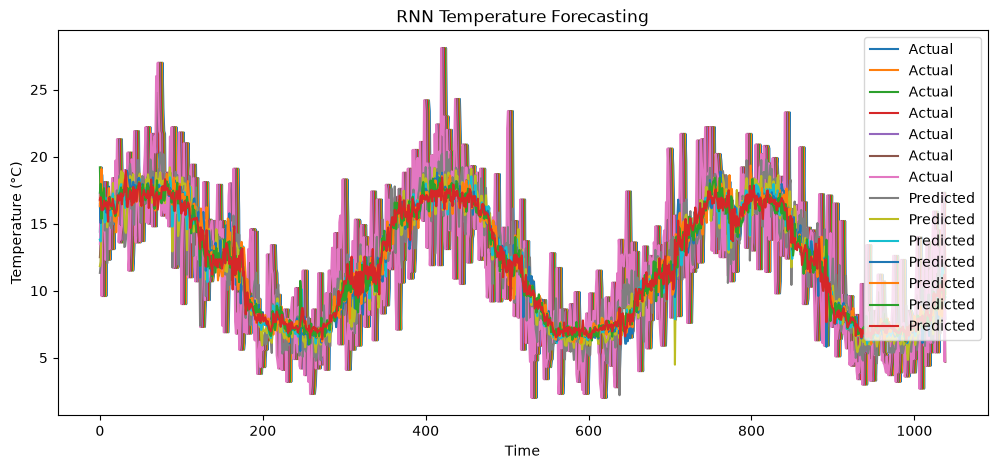

In [69]:
import matplotlib.pyplot as plt

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    y_test_original,
    label="Actual"
)

plt.plot(
    RNN_predictions_original,
    label="Predicted"
)

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.title("RNN Temperature Forecasting")

plt.legend()
plt.show()

In [70]:
mae_rnn = mean_absolute_error(y_test_original, RNN_predictions_original)

rmse_rnn = np.sqrt(mean_squared_error(y_test_original, RNN_predictions_original))
               
r2_rnn = r2_score(y_test_original, RNN_predictions_original)



print ('RNN MAE:', mae_rnn)


print ('RNN RMSE:', rmse_rnn)


print ('RNN - R2 SCORE:', r2_rnn)


RNN MAE: 2.436609746231988
RNN RMSE: 3.0754814159393744
RNN - R2 SCORE: 0.6164719271242198


Next I will test the model in the data of each of the four rest stations. First I take the data from station Christchurch, Kyle St EWS  

In [71]:
df_CK = df_all[df_all["Station"] == "CK"]

In [72]:
print(df_CK.head())
print(df_CK.shape)
df_CK.describe()

          Observation time UTC_x  evap_penman_open  evap_penman_pet  \
27249  2006-02-11 20:00:00+00:00               4.3              4.6   
27250  2006-02-12 20:00:00+00:00               9.3              6.8   
27251  2006-02-13 20:00:00+00:00               4.3              4.4   
27252  2006-02-14 20:00:00+00:00               3.4              2.4   
27253  2006-02-15 20:00:00+00:00               2.8              3.6   

       evap_priestley_taylor  Rainfall [mm]  Speed [m/s]  \
27249                    4.3            0.0         3.01   
27250                    4.8            0.0         3.17   
27251                    3.8            0.0         4.10   
27252                    1.6            0.0         2.34   
27253                    3.6            0.0         3.10   

       Maximum Temperature [Deg C]  Minimum Temperature [Deg C]  \
27249                         23.9                         17.2   
27250                         29.4                         14.5   
27251      

,evap_penman_open,evap_penman_pet,evap_priestley_taylor,Rainfall [mm],Speed [m/s],Maximum Temperature [Deg C],Minimum Temperature [Deg C],Mean Temperature [Deg C]_x
count,6949.000000,6949.000000,6949.000000,6949.000000,6949.000000,6949.000000,6949.000000,6949.000000
mean,2.958469,2.470471,1.816319,1.766125,2.643072,18.060296,7.526954,12.818621
std,2.000094,1.845294,1.739735,5.743443,0.948577,5.499416,5.031469,4.845146
min,0.000000,0.000000,0.000000,0.000000,0.450000,1.200000,-5.800000,-1.900000
25%,1.500000,0.900000,0.200000,0.000000,1.940000,13.900000,3.700000,9.100000
50%,2.500000,2.000000,1.300000,0.000000,2.570000,17.700000,7.700000,12.800000
75%,4.100000,3.800000,3.100000,0.400000,3.230000,21.500000,11.500000,16.400000
max,12.600000,9.000000,6.900000,122.800000,8.180000,37.000000,22.200000,28.100000


In [73]:
# Check for missing values
print(df_CK.isnull().sum())

# Convert the data type of the date column in the dataset to Date format
df_CK["Date"] = pd.to_datetime(df_CK["Observation time UTC_x"], format="ISO8601",
    utc=True
)

# Sort the dataframe according to the date
df_CK = df_CK.sort_values("Date").reset_index(drop=True) # index is reset and old index is dropped

Observation time UTC_x         0
evap_penman_open               0
evap_penman_pet                0
evap_priestley_taylor          0
Rainfall [mm]                  0
Speed [m/s]                    0
Maximum Temperature [Deg C]    0
Minimum Temperature [Deg C]    0
Mean Temperature [Deg C]_x     0
Station                        0
dtype: int64


In [74]:
X_CK = df_CK[["evap_penman_open", "evap_penman_pet", "evap_priestley_taylor", "Rainfall [mm]", "Speed [m/s]", 
"Maximum Temperature [Deg C]",
"Minimum Temperature [Deg C]" ,  
"Mean Temperature [Deg C]_x"  
]]
test_CK = X_CK



print("Test_CK:", test_CK.shape)


Test_CK: (6949, 8)


In [75]:
# Normalize temperature
# Scale the four input features


X_CK_scaled = X_scaler.fit_transform(test_CK)


y_CK_scaled = y_scaler.fit_transform(
   test_CK.iloc[:, -1].values.reshape(-1, 1)
)
print(X_CK_scaled.shape)
print(y_CK_scaled.shape)


(6949, 8)
(6949, 1)


In [76]:



sequence_length = 30




X_CK_test, y_CK_test = create_sequences(
    X_CK_scaled,
    y_CK_scaled,
    sequence_length
)



print("X_test:", X_CK_test.shape)
print("y_test:", y_CK_test.shape)

X_test: (6913, 30, 8)
y_test: (6913, 7)


In [77]:

# Predict temperature
RNN_predictions_CK = RNN_model_7.predict(X_CK_test)

# Convert them back to °C
RNN_predictions_original_CK = y_scaler.inverse_transform(
    RNN_predictions_CK
)

y_CK_test_original = y_scaler.inverse_transform(
    y_CK_test
)

217/217 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [78]:
# Compare actual vs predicted
RNN_results_CK = pd.DataFrame({
    "Actual_Temperature": y_CK_test_original.flatten(),
    "Predicted_Temperature": RNN_predictions_original_CK.flatten()
})

print(RNN_results_CK.head(20))

    Actual_Temperature  Predicted_Temperature
0                 12.7              13.597613
1                 17.0              15.506454
2                 13.8              15.424299
3                 14.2              16.406828
4                 14.8              15.319690
5                 14.5              14.105036
6                 15.9              14.422898
7                 17.0              14.043384
8                 13.8              13.974136
9                 14.2              14.262558
10                14.8              14.536233
11                14.5              15.240160
12                15.9              13.752615
13                15.5              14.779510
14                13.8              17.885208
15                14.2              16.432095
16                14.8              14.692479
17                14.5              14.556976
18                15.9              15.318253
19                15.5              14.409779


In [79]:
mae_rnn_CK = mean_absolute_error(y_CK_test_original, RNN_predictions_original_CK)

rmse_rnn_CK = np.sqrt(mean_squared_error(y_CK_test_original, RNN_predictions_original_CK))
               
r2_rnn_CK = r2_score(y_CK_test_original, RNN_predictions_original_CK)



print ('RNN MAE CK:', mae_rnn_CK)


print ('RNN RMSE CK:', rmse_rnn_CK)


print ('RNN - R2 SCORE CK:', r2_rnn_CK)

RNN MAE CK: 2.344592152460495
RNN RMSE CK: 2.9706320956006
RNN - R2 SCORE CK: 0.6244150887125927


For the next I test the data for the dataset ASHBURTON AERO AWS

In [80]:
df_AA = df_all[df_all["Station"] == "AA"]

print(df_AA.head())
print(df_AA.shape)
df_AA.describe()

# Check for missing values
print(df_AA.isnull().sum())

# Convert the data type of the date column in the dataset to Date format
df_AA["Date"] = pd.to_datetime(df_AA["Observation time UTC_x"], format="ISO8601",
    utc=True
)

# Sort the dataframe according to the date
df_AA = df_AA.sort_values("Date").reset_index(drop=True) # index is reset and old index is dropped


X_AA = df_AA[["evap_penman_open", "evap_penman_pet", "evap_priestley_taylor", "Rainfall [mm]", "Speed [m/s]", 
"Maximum Temperature [Deg C]",
"Minimum Temperature [Deg C]" ,  
"Mean Temperature [Deg C]_x"  
]]
test_AA = X_AA



print("Test_AA:", test_AA.shape)


# Normalize temperature
# Scale the four input features


X_AA_scaled = X_scaler.transform(test_AA)


y_AA_scaled = y_scaler.transform(
   test_AA.iloc[:, -1].values.reshape(-1, 1)
)
print(X_AA_scaled.shape)
print(y_AA_scaled.shape)

sequence_length = 30




X_AA_test, y_AA_test = create_sequences(
    X_AA_scaled,
    y_AA_scaled,
    sequence_length
)



print("X_test:", X_AA_test.shape)
print("y_test:", y_AA_test.shape)

# Predict temperature
RNN_predictions_AA = RNN_model_7.predict(X_AA_test)

# Convert them back to °C
RNN_predictions_original_AA = y_scaler.inverse_transform(
    RNN_predictions_AA
)

y_AA_test_original = y_scaler.inverse_transform(
    y_AA_test
)

# Compare actual vs predicted
RNN_results_AA = pd.DataFrame({
    "Actual_Temperature": y_AA_test_original.flatten(),
    "Predicted_Temperature": RNN_predictions_original_AA.flatten()
})

print(RNN_results_AA.head(20))


mae_rnn_AA = mean_absolute_error(y_AA_test_original, RNN_predictions_original_AA)

rmse_rnn_AA = np.sqrt(mean_squared_error(y_AA_test_original, RNN_predictions_original_AA))
               
r2_rnn_AA = r2_score(y_AA_test_original, RNN_predictions_original_AA)



print ('RNN MAE AA:', mae_rnn_AA)


print ('RNN RMSE AA:', rmse_rnn_AA)


print ('RNN - R2 SCORE AA:', r2_rnn_AA)

      Observation time UTC_x  evap_penman_open  evap_penman_pet  \
0  2006-02-11 20:00:00+00:00               6.5              5.5   
1  2006-02-12 20:00:00+00:00               8.6              6.3   
2  2006-02-13 20:00:00+00:00               4.5              4.3   
3  2006-02-14 20:00:00+00:00               2.9              2.3   
4  2006-02-15 20:00:00+00:00               2.0              3.3   

   evap_priestley_taylor  Rainfall [mm]  Speed [m/s]  \
0                    4.0            0.0         3.01   
1                    4.2            0.0         3.17   
2                    3.4            0.0         4.10   
3                    1.7            0.4         2.34   
4                    3.5            0.0         3.10   

   Maximum Temperature [Deg C]  Minimum Temperature [Deg C]  \
0                         26.7                         14.5   
1                         29.3                         12.5   
2                         20.6                         10.3   
3       

This is to test the station Rangiora EWS

In [81]:
df_RE = df_all[df_all["Station"] == "RE"]

print(df_RE.head())
print(df_RE.shape)
df_RE.describe()

# Check for missing values
print(df_RE.isnull().sum())

# Convert the data type of the date column in the dataset to Date format
df_RE["Date"] = pd.to_datetime(df_RE["Observation time UTC_x"], format="ISO8601",
    utc=True
)

# Sort the dataframe according to the date
df_RE = df_RE.sort_values("Date").reset_index(drop=True) # index is reset and old index is dropped


X_RE = df_RE[["evap_penman_open", "evap_penman_pet", "evap_priestley_taylor", "Rainfall [mm]", "Speed [m/s]", 
"Maximum Temperature [Deg C]",
"Minimum Temperature [Deg C]" ,  
"Mean Temperature [Deg C]_x"  
]]
test_RE = X_RE



print("Test_RE:", test_RE.shape)


# Normalize temperature
# Scale the four input features


X_RE_scaled = X_scaler.transform(test_RE)


y_RE_scaled = y_scaler.transform(
   test_RE.iloc[:, -1].values.reshape(-1, 1)
)
print(X_RE_scaled.shape)
print(y_RE_scaled.shape)

sequence_length = 30




X_RE_test, y_RE_test = create_sequences(
    X_RE_scaled,
    y_RE_scaled,
    sequence_length
)



print("X_test:", X_RE_test.shape)
print("y_test:", y_RE_test.shape)

# Predict temperature
RNN_predictions_RE = RNN_model_7.predict(X_RE_test)

# Convert them back to °C
RNN_predictions_original_RE = y_scaler.inverse_transform(
    RNN_predictions_RE
)

y_RE_test_original = y_scaler.inverse_transform(
    y_RE_test
)

# Compare actual vs predicted
RNN_results_RE = pd.DataFrame({
    "Actual_Temperature": y_RE_test_original.flatten(),
    "Predicted_Temperature": RNN_predictions_original_RE.flatten()
})

print(RNN_results_RE.head(20))


mae_rnn_RE = mean_absolute_error(y_RE_test_original, RNN_predictions_original_RE)

rmse_rnn_RE = np.sqrt(mean_squared_error(y_RE_test_original, RNN_predictions_original_RE))
               
r2_rnn_RE = r2_score(y_RE_test_original, RNN_predictions_original_RE)



print ('RNN MAE RE:', mae_rnn_RE)


print ('RNN RMSE RE:', rmse_rnn_RE)


print ('RNN - R2 SCORE RE:', r2_rnn_RE)


          Observation time UTC_x  evap_penman_open  evap_penman_pet  \
14016  2006-02-11 20:00:00+00:00               4.6              4.7   
14017  2006-02-12 20:00:00+00:00               8.1              6.5   
14018  2006-02-13 20:00:00+00:00               3.2              4.1   
14019  2006-02-14 20:00:00+00:00               2.9              2.1   
14020  2006-02-15 20:00:00+00:00               1.9              3.2   

       evap_priestley_taylor  Rainfall [mm]  Speed [m/s]  \
14016                    4.3            0.0         3.56   
14017                    4.8            0.0         3.51   
14018                    4.0            0.0         3.76   
14019                    1.4            0.0         2.33   
14020                    3.5            0.0         3.29   

       Maximum Temperature [Deg C]  Minimum Temperature [Deg C]  \
14016                         25.9                         14.9   
14017                         28.2                         12.3   
14018      

This is to test the station Hanmer Forest EWS 

In [82]:
df_HF = df_all[df_all["Station"] == "HF"]

print(df_HF.head())
print(df_HF.shape)
df_HF.describe()

# Check for missing values
print(df_HF.isnull().sum())

# Convert the data type of the date column in the dataset to Date format
df_HF["Date"] = pd.to_datetime(df_HF["Observation time UTC_x"], format="ISO8601",
    utc=True
)

# Sort the dataframe according to the date
df_HF = df_HF.sort_values("Date").reset_index(drop=True) # index is reset and old index is dropped

X_HF = df_HF[["evap_penman_open", "evap_penman_pet", "evap_priestley_taylor", "Rainfall [mm]", "Speed [m/s]", 
"Maximum Temperature [Deg C]",
"Minimum Temperature [Deg C]" ,  
"Mean Temperature [Deg C]_x"  
]]
test_HF = X_HF


print("Test_HF:", test_HF.shape)

# Normalize temperature
# Scale the four input features

X_HF_scaled = X_scaler.transform(test_HF)

y_HF_scaled = y_scaler.transform(
   test_HF.iloc[:, -1].values.reshape(-1, 1)
)
print(X_HF_scaled.shape)
print(y_HF_scaled.shape)

sequence_length = 30



X_HF_test, y_HF_test = create_sequences(
    X_HF_scaled,
    y_HF_scaled,
    sequence_length
)


print("X_test:", X_HF_test.shape)
print("y_test:", y_HF_test.shape)

# Predict temperature
RNN_predictions_HF = RNN_model_7.predict(X_HF_test)

# Convert them back to °C
RNN_predictions_original_HF = y_scaler.inverse_transform(
    RNN_predictions_HF
)

y_HF_test_original = y_scaler.inverse_transform(
    y_HF_test
)

# Compare actual vs predicted
RNN_results_HF = pd.DataFrame({
    "Actual_Temperature": y_HF_test_original.flatten(),
    "Predicted_Temperature": RNN_predictions_original_HF.flatten()
})

print(RNN_results_HF.head(20))

mae_rnn_HF = mean_absolute_error(y_HF_test_original, RNN_predictions_original_HF)

rmse_rnn_HF = np.sqrt(mean_squared_error(y_HF_test_original, RNN_predictions_original_HF))
               
r2_rnn_HF = r2_score(y_HF_test_original, RNN_predictions_original_HF)


print ('RNN MAE HF:', mae_rnn_HF)

print ('RNN RMSE HF:', rmse_rnn_HF)

print ('RNN - R2 SCORE HF:', r2_rnn_HF)



          Observation time UTC_x  evap_penman_open  evap_penman_pet  \
21096  2006-02-20 20:00:00+00:00               4.1              4.6   
21097  2006-02-21 20:00:00+00:00               4.1              4.0   
21098  2006-02-22 20:00:00+00:00               3.8              2.7   
21099  2006-02-23 20:00:00+00:00               3.7              2.8   
21100  2006-02-24 20:00:00+00:00               3.1              3.6   

       evap_priestley_taylor  Rainfall [mm]  Speed [m/s]  \
21096                    4.3            0.0         2.42   
21097                    3.5            0.0         2.84   
21098                    1.6            0.0         3.29   
21099                    1.9            5.4         1.37   
21100                    3.5            0.0         1.61   

       Maximum Temperature [Deg C]  Minimum Temperature [Deg C]  \
21096                         26.5                          8.4   
21097                         27.9                          8.0   
21098      

Next I create a table to compare the results between the station 

In [83]:
import pandas as pd

comparison_table = pd.DataFrame({
    "Dataset": ["Test_Christchurch Aero", "Christchurch, Kyle St EWS ", "ASHBURTON AERO AWS", "Rangiora EWS", "Hanmer Forest EWS"],

    "RNN MAE": [
        mae_rnn,
        mae_rnn_CK,
        mae_rnn_AA, 
        mae_rnn_RE, 
        mae_rnn_HF
       
    ],

   
    "RNN RMSE": [
        rmse_rnn,
        rmse_rnn_CK,
        rmse_rnn_AA,
        rmse_rnn_RE, 
        rmse_rnn_HF, 
       
    ],

    "R2 SCORE": [
        r2_rnn,
        r2_rnn_CK, 
        r2_rnn_AA, 
        r2_rnn_RE, 
        r2_rnn_HF
           
        ],
    
       
   
    

    })
comparison_table



,Dataset,RNN MAE,RNN RMSE,R2 SCORE
0,Test_Christchurch Aero,2.436610,3.075481,0.616472
1,"Christchurch, Kyle St EWS",2.344592,2.970632,0.624415
2,ASHBURTON AERO AWS,2.691967,3.336585,0.530178
3,Rangiora EWS,2.500411,3.102176,0.562108
4,Hanmer Forest EWS,3.416486,4.218701,0.395089


Save the table to the folder

In [84]:
comparison_table.to_csv("test result comparison table.csv")

2.3 Summary and Comparison 
Report the final model configuration and justify all architectural and training choices, 
including the input-window size, number of recurrent layers, number of hidden units, 
dropout rate, learning rate, batch size, number of training epochs, and other relevant 
hyperparameters.  
Based on the comparison table, analyse the model's forecasting performance across all 
five stations, highlighting differences between the source station and the four other 
stations. Discuss the model's ability to generalise across weather stations and identify 
the key observations from the experimental results. 

First of all, about selecting the model and develop the architectural of the model. First of all, because this model is to forecast 7 days so when I created the sequence I must make sure that the sequence produce the output y of seven days. 
Then I used the train and valid data to choose and fine tune the forecast model. I tried with RNN, LSTM and GRU. In each of these model and I select different input window such as 7, 14, 30 and 60. So depending on the model, the window that provide the best results are different. Then I also tried another parameters such as number of layers, number of units, drop out, learning rates, etc...For most of the cases I see that learning rate of 0.0001 provided better results and in some cases drop-out rate of 0.2 gave better results. In the end, for each model I identified the best performned model then I compared those three models and in the end I selected RNN model as they are provided the best results. Specifically, the configuration of the model as follows: sequence length: 30, layer 1, no dropout, no of unit, 64, batch size 32, epoches 30, no early stop, learning rate 0.0001. When I fine tune the model I can see that with the changes of the parameter, the models' peformance overall did not change much, I think because of the small size of the train data, and also because this is weather data which are quite in pattern so things like sequence might not make much change. 

Then I used the model to test the test data in the dataset that is used to train the model and also the dataset in other stations. I can see as the table above shows the accuracy is highest in the station of which data was used to train the model and it decreased in other stations. The levels of decrease are different between stations, such as Christchurch, Kyle St EWS is highest, followed by Rangiora EWS and ASHBURTON AERO AWS while Hanmer Forest EWS	 is the lowest. So I think the level of generalization of this model across different station depend on each station and for some stations they are not really high. I think first of all, the model was developed from a small size of data so the quality of model itself has some limitations. When I refer to the location of the stations it seems that the father the location of the station, the less the level of accuracy is which makes sense as my training model only used data from one station and weather in each location can be very different. So my key observation from this results is that a model developed from one station, one location for weather forecast might be not really accurate. That the location of where the data is taken can affect the quality of the model developed. 

Overall when I try d